# Análise de Redes Sociais com Métricas de Grafos

**Disciplina:** Teoria e Aplicação de Grafos (TAG) — CIC0199 - Turma 01 - 2026/2

**Docente:** Prof. Díbio Leandro Borges

**Integrantes:**
- Matheus Duarte da Silva - 211062277
- Suyanne Sara Miranda Silva — 222006445 

## Objetivo

Analisar as estruturas de redes sociais usando de métricas para grafos, avaliando a importância e potencial de difusão de informação de usuários em uma amostra real do Facebook


## Coleta dos Dados

### Configuração de bibliotecas e caminhos


In [1]:
import colorsys
import random
import re
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from pyvis.network import Network
from pyvis.options import Layout

In [2]:
# Configuração de diretórios e caminhos
DATASET_PATH = Path("../data/facebook_combined.txt.gz")

OUTPUT_METRICS_DIR = Path("../metrics")
OUTPUT_HTML_DIR = Path("../metrics/html")

OUTPUT_METRICS_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_HTML_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_IMAGES_DIR = Path("../images")
OUTPUT_IMAGES_DIR.mkdir(parents=True, exist_ok=True)

# Sementes e tamanho da amostra
RANDOM_SEED = 17919131
SAMPLE_SIZE = 404

### Carrega a rede completa do Facebook


In [3]:
# Carrega todo o grafo do Facebook
G = nx.read_edgelist(DATASET_PATH, nodetype=int)

print("Grafo completo carregada")
print(f"Total de nós (usuários): {G.number_of_nodes()}")
print(f"Total de arestas (conexões de amizade): {G.number_of_edges()}")

Grafo completo carregada
Total de nós (usuários): 4039
Total de arestas (conexões de amizade): 88234


### Amostragem de 404 vértices


In [4]:
# Gerador pseudo-aleatório com semente fixa para garantir reprodutibilidade
rng = random.Random(RANDOM_SEED)

# Seleciona 404 nós aleatórios
selected_nodes = rng.sample(list(G.nodes()), SAMPLE_SIZE)

print(f"Quantidade de nós selecionados: {len(selected_nodes)}")
print("Amostra dos 10 primeiros nós selecionados:", selected_nodes[:10])

Quantidade de nós selecionados: 404
Amostra dos 10 primeiros nós selecionados: [2479, 3849, 2911, 1920, 1058, 3718, 3927, 2034, 2694, 3080]


## Construção do grafo

### Representa a rede amostrada


In [5]:
# Pega o subgrafo e mantém os 404 nós e todas as arestas existentes entre eles
subgraph_sample = G.subgraph(selected_nodes).copy()

node_count = subgraph_sample.number_of_nodes()
edge_count = subgraph_sample.number_of_edges()
component_count = nx.number_connected_components(subgraph_sample)
isolated_node_count = len(list(nx.isolates(subgraph_sample)))

print(f"Nós no subgrafo amostrado: {node_count}")
print(f"Arestas no subgrafo amostrado: {edge_count}")
print(f"Número de componentes conexos: {component_count}")
print(f"Nós isolados (grau 0): {isolated_node_count}")

Nós no subgrafo amostrado: 404
Arestas no subgrafo amostrado: 824
Número de componentes conexos: 99
Nós isolados (grau 0): 71


### Visualização inicial do subgrafo amostrado


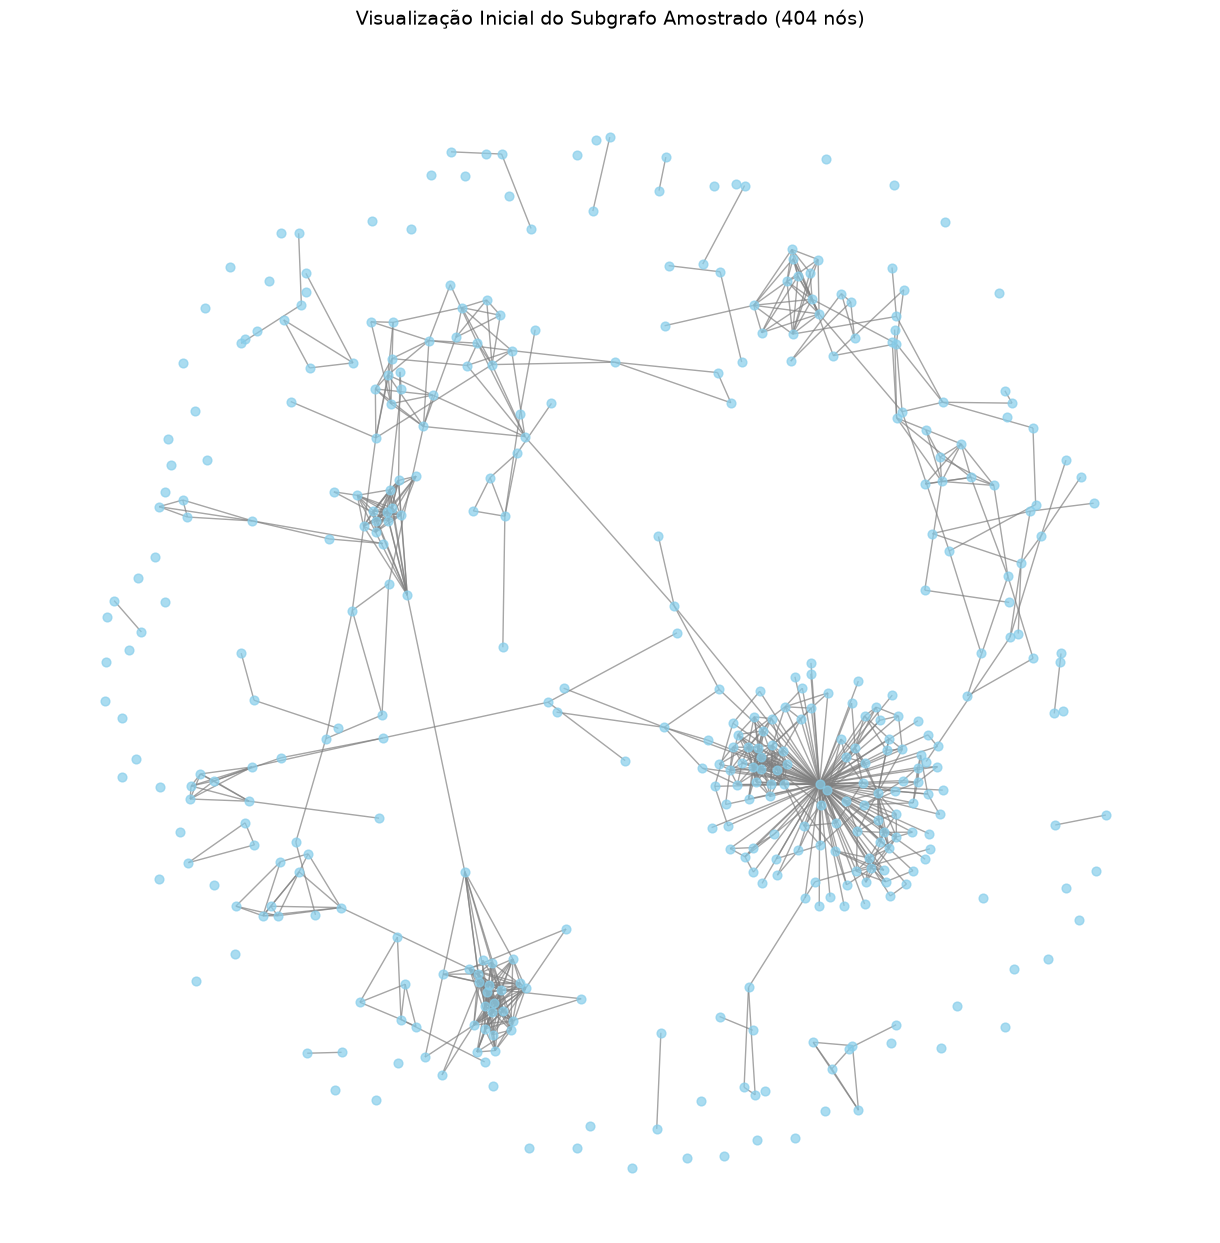

In [6]:
plt.figure(figsize=(12, 12))

nodes_positions = nx.spring_layout(
    subgraph_sample, seed=RANDOM_SEED, k=0.15, iterations=50
)

nx.draw(
    subgraph_sample,
    nodes_positions,
    node_size=40,
    node_color="skyblue",
    edge_color="gray",
    alpha=0.7,
    with_labels=False,
)

plt.title("Visualização Inicial do Subgrafo Amostrado (404 nós)", fontsize=14)

plt.axis("off")

plt.show()

## Extração de métricas do grafo

### Mapea as comunidades pelo algoritmo de Louvain


In [7]:
# Identifica grupos de nós que têm mais conexões entre si do que com o resto da rede
communities = nx.community.louvain_communities(subgraph_sample, seed=RANDOM_SEED)

# Dicionário mapeando cada nó para o índice da sua comunidade
community_by_node = {
    node: i for i, community in enumerate(communities) for node in community
}

community_sizes = sorted([len(c) for c in communities], reverse=True)

print(f"Quantidade de comunidades identificadas: {len(communities)}")
print("Tamanho das 5 maiores comunidades:", community_sizes[:5])

Quantidade de comunidades identificadas: 105
Tamanho das 5 maiores comunidades: [69, 30, 28, 25, 19]


### Visualização das comunidades


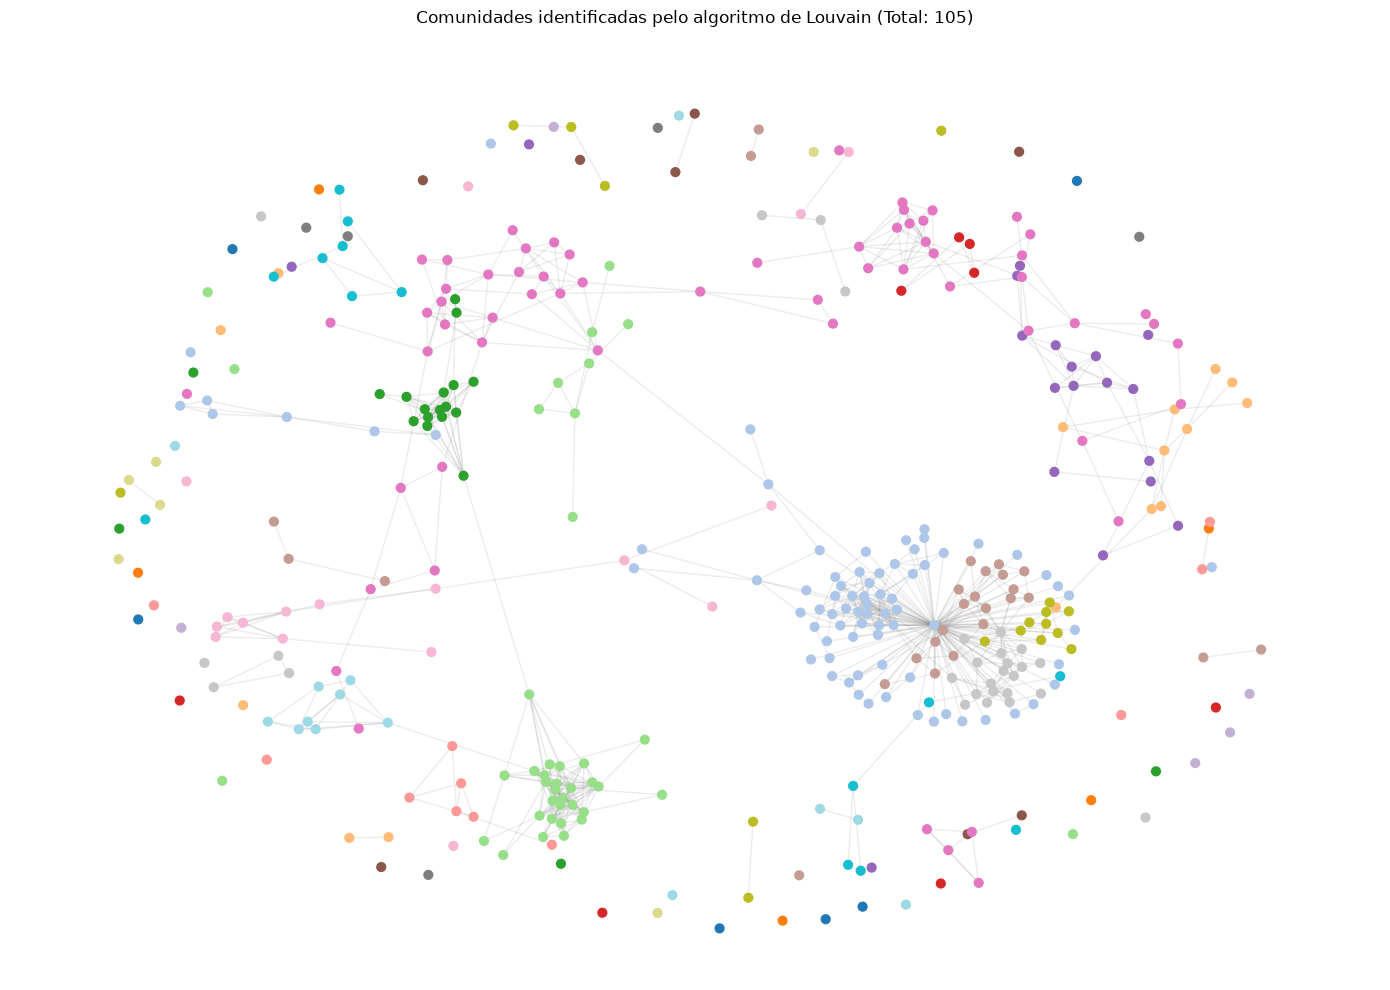

In [8]:
# Mapa em cores das comunidades de Louvain
community_colors = [community_by_node[node] for node in subgraph_sample.nodes()]

plt.figure(figsize=(14, 10))
nx.draw_networkx_edges(subgraph_sample, nodes_positions, alpha=0.15, edge_color="gray")

nx.draw_networkx_nodes(
    subgraph_sample,
    nodes_positions,
    node_color=community_colors,
    cmap=plt.cm.tab20,
    node_size=40,
)

plt.title(
    f"Comunidades identificadas pelo algoritmo de Louvain (Total: {len(communities)})"
)

plt.tight_layout()
plt.axis("off")

plt.show()

### Calculando as medidas de centralidade

Calcula as métricas de centralidade para cada nó do subgrafo amostrado:

- **Grau de centralidade (Degree Centrality):** número de conexões normalizado pelo número total de outros nós.
- **Centralidade de intermediação (Betweenness Centrality):** frequência com que um nó se encontra nos caminhos mais curtos entre outros pares (pontes/gatekeepers).
- **Centralidade de proximidade (Closeness Centrality):** proximidade média aos nós alcançáveis (velocidade de propagação).
- **Centralidade de autovetor (Eigenvector Centrality):** influência proporcional à relevância dos próprios vizinhos conectados (prestígio).


In [9]:
# Grau: quantas conexões diretas um nó possui, normalizadas pelo tamanho do grafo
nodes_degrees = nx.degree_centrality(subgraph_sample)

# Intermediação: quanto um nó participa dos caminhos mínimos entre outros nós
nodes_betweenness = nx.betweenness_centrality(subgraph_sample)

# Proximidade: quão perto um nó está dos demais, considerando os caminhos mínimos
nodes_closeness = nx.closeness_centrality(subgraph_sample)

# Centralidade de Autovetor: calcula a importância com base na importância dos vizinhos
eigenvector_centrality_scores = nx.eigenvector_centrality(
    subgraph_sample, max_iter=1000
)

print("Cálculo de centralidades:")
print(
    "Top 3 - Grau:", sorted(nodes_degrees.items(), key=lambda x: x[1], reverse=True)[:3]
)
print(
    "Top 3 - Intermediação:",
    sorted(nodes_betweenness.items(), key=lambda x: x[1], reverse=True)[:3],
)
print(
    "Top 3 - Proximidade:",
    sorted(nodes_closeness.items(), key=lambda x: x[1], reverse=True)[:3],
)
print(
    "Top 3 - Autovetor:",
    sorted(eigenvector_centrality_scores.items(), key=lambda x: x[1], reverse=True)[:3],
)

Cálculo de centralidades:
Top 3 - Grau: [(107, 0.2803970223325062), (2328, 0.05707196029776675), (2511, 0.04714640198511166)]
Top 3 - Intermediação: [(107, 0.11699313899602787), (1666, 0.04438107230596398), (3111, 0.04218894837575627)]
Top 3 - Proximidade: [(107, 0.21414291598436824), (1666, 0.1607699095688114), (1450, 0.14816050489674776)]
Top 3 - Autovetor: [(107, 0.5657275904369735), (1622, 0.18596196590635697), (1377, 0.1780702178462158)]


### Atribuindo as métricas aos vértices do grafo


In [10]:
# Adiciona as métricas como atributos dos vértices no grafo
nx.set_node_attributes(
    G=subgraph_sample, values=community_by_node, name="Comunidades de Nós"
)
nx.set_node_attributes(
    G=subgraph_sample, values=nodes_degrees, name="Grau de Centralidade"
)
nx.set_node_attributes(
    G=subgraph_sample, values=nodes_betweenness, name="Centralidade de Intermediação"
)
nx.set_node_attributes(
    G=subgraph_sample, values=nodes_closeness, name="Centralidade de Proximidade"
)
nx.set_node_attributes(
    G=subgraph_sample,
    values=eigenvector_centrality_scores,
    name="Centralidade de Autovetor",
)

### Exportando os dados

In [11]:
# Exporta o grafo completo para o Gephi (.gexf)
gexf_path = OUTPUT_METRICS_DIR / "graph_metrics.gexf"

nx.write_gexf(subgraph_sample, gexf_path)

print(f"Grafo exportado para o Gephi: {gexf_path}")

Grafo exportado para o Gephi: ../metrics/graph_metrics.gexf


In [12]:
# Consolida todas as métricas em formato DataFrame com Pandas
df_metrics = pd.DataFrame(
    {
        "no": list(subgraph_sample.nodes()),
        "comunidade": [community_by_node[no] for no in subgraph_sample.nodes()],
        "grau": [nodes_degrees[no] for no in subgraph_sample.nodes()],
        "intermediacao": [nodes_betweenness[no] for no in subgraph_sample.nodes()],
        "proximidade": [nodes_closeness[no] for no in subgraph_sample.nodes()],
        "autovetor": [
            eigenvector_centrality_scores[no] for no in subgraph_sample.nodes()
        ],
    }
)

# Exporta para CSV
csv_path = OUTPUT_METRICS_DIR / "graph_metrics.csv"
df_metrics.to_csv(csv_path, index=False)

print(f"Métricas salvas em CSV: {csv_path}")

df_metrics.head(10)

Métricas salvas em CSV: ../metrics/graph_metrics.csv


,no,comunidade,grau,intermediacao,proximidade,autovetor
0,29,0,0.000000,0.000000,0.000000,2.737947e-73
1,2083,24,0.019851,0.000057,0.036671,2.213007e-06
2,38,19,0.002481,0.000000,0.008739,1.774296e-37
3,2090,24,0.027295,0.000075,0.037524,2.774131e-06
4,2092,24,0.004963,0.000011,0.029606,2.507339e-07
5,2096,29,0.004963,0.000000,0.041109,2.763482e-05
6,51,1,0.000000,0.000000,0.000000,2.737947e-73
7,54,2,0.000000,0.000000,0.000000,2.737947e-73
8,2112,24,0.022333,0.000069,0.030588,1.765158e-06
9,65,3,0.000000,0.000000,0.000000,2.737947e-73


## Vizualização das métricas das métricas extraídas

### Grafos estáticos


In [13]:
# Função auxiliar para visualizar as medidas de centralidade destacando os vértices com maiores valores
def display_centrality(
    G: nx.Graph, pos: dict, metrics: dict, metric_name: str, top_k: int = 10
):
    top_k_nodes = sorted(metrics.items(), key=lambda item: item[1], reverse=True)[
        :top_k
    ]

    centrality_values = [metrics[node] for node in G.nodes()]
    top_nodes = [node for node, _ in top_k_nodes]

    plt.figure(figsize=(16, 12))

    nx.draw_networkx_edges(G, pos, alpha=0.08, edge_color="gray")

    node_visualization = nx.draw_networkx_nodes(
        G, pos, node_color=centrality_values, cmap=plt.cm.plasma, node_size=25
    )

    # Desenha os nós mais importantes com destaque em vermelho e tamanho maior
    nx.draw_networkx_nodes(
        G, pos, nodelist=top_nodes, node_color="red", node_size=180, edgecolors="black"
    )

    node_labels = {node: f"{node}\n{metrics[node]:.4f}" for node in top_nodes}

    nx.draw_networkx_labels(
        G,
        pos,
        labels=node_labels,
        font_size=9,
        font_weight="bold",
        bbox={"facecolor": "white", "edgecolor": "gray", "alpha": 0.9, "pad": 2},
    )

    plt.colorbar(node_visualization, label=f"Centralidade: {metric_name}")
    plt.title(f"{metric_name} — Top {top_k} nós", fontsize=14)

    plt.axis("off")
    plt.tight_layout()

    plt.show()

    return top_k_nodes

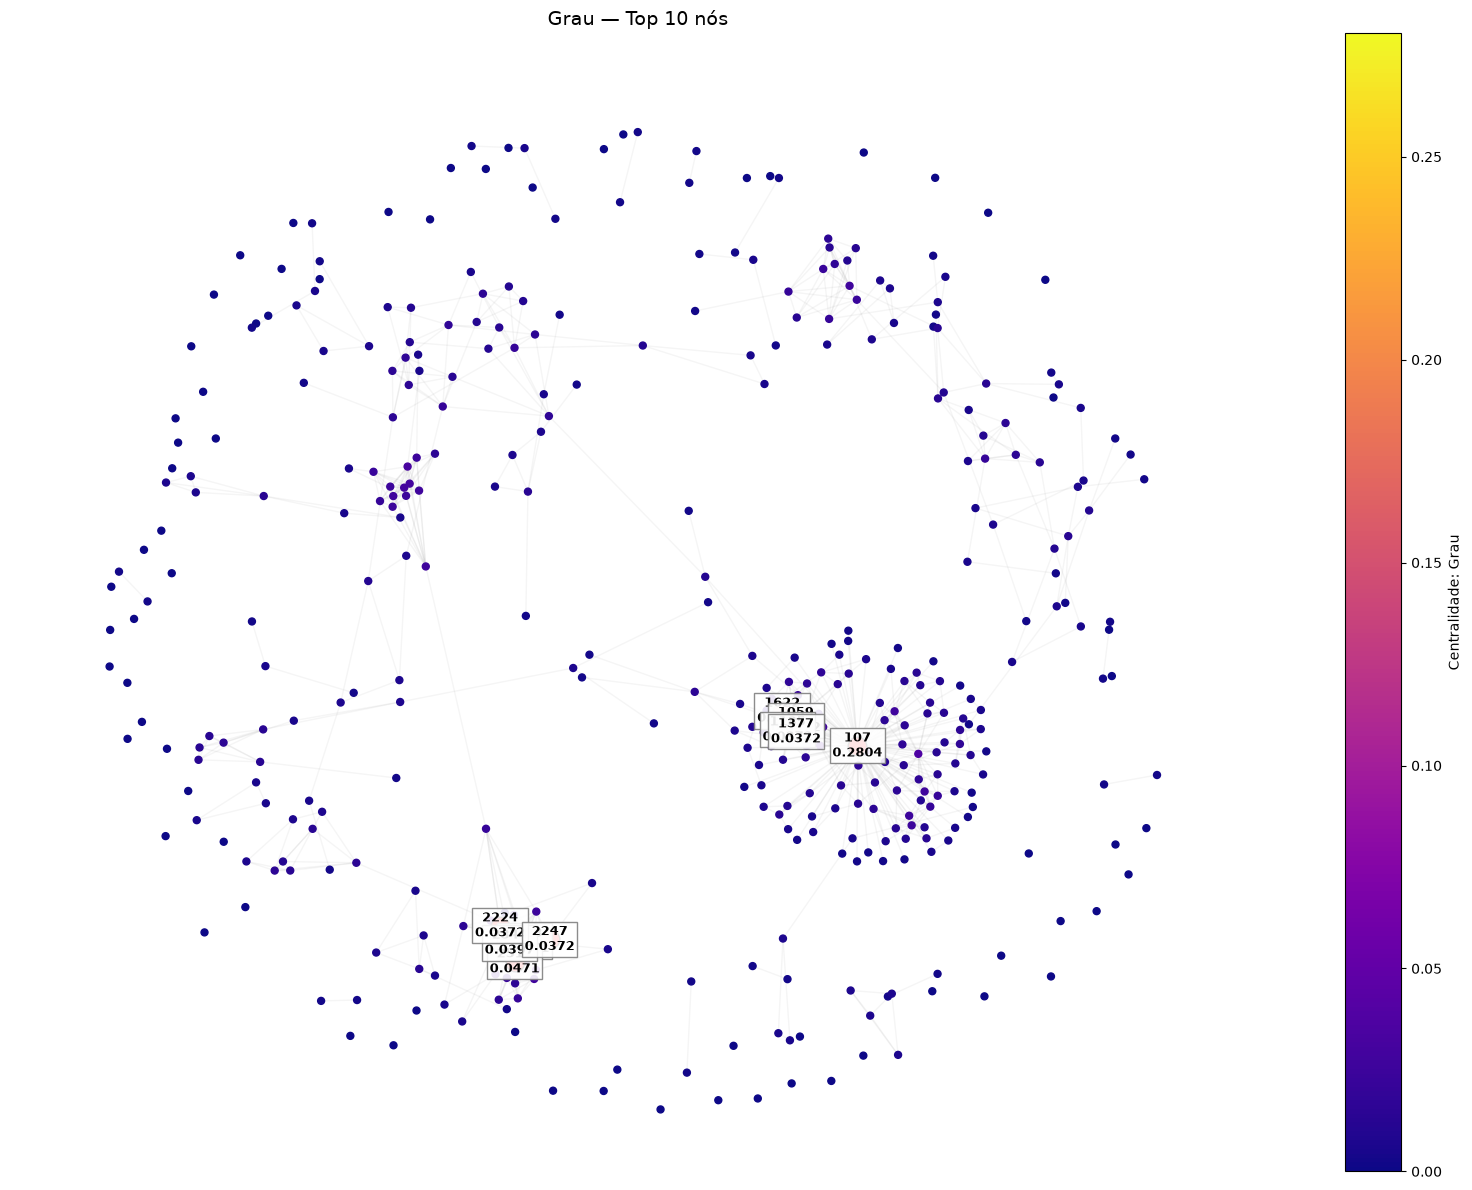

In [14]:
top_degree_centrality = display_centrality(
    G=subgraph_sample, pos=nodes_positions, metrics=nodes_degrees, metric_name="Grau"
)

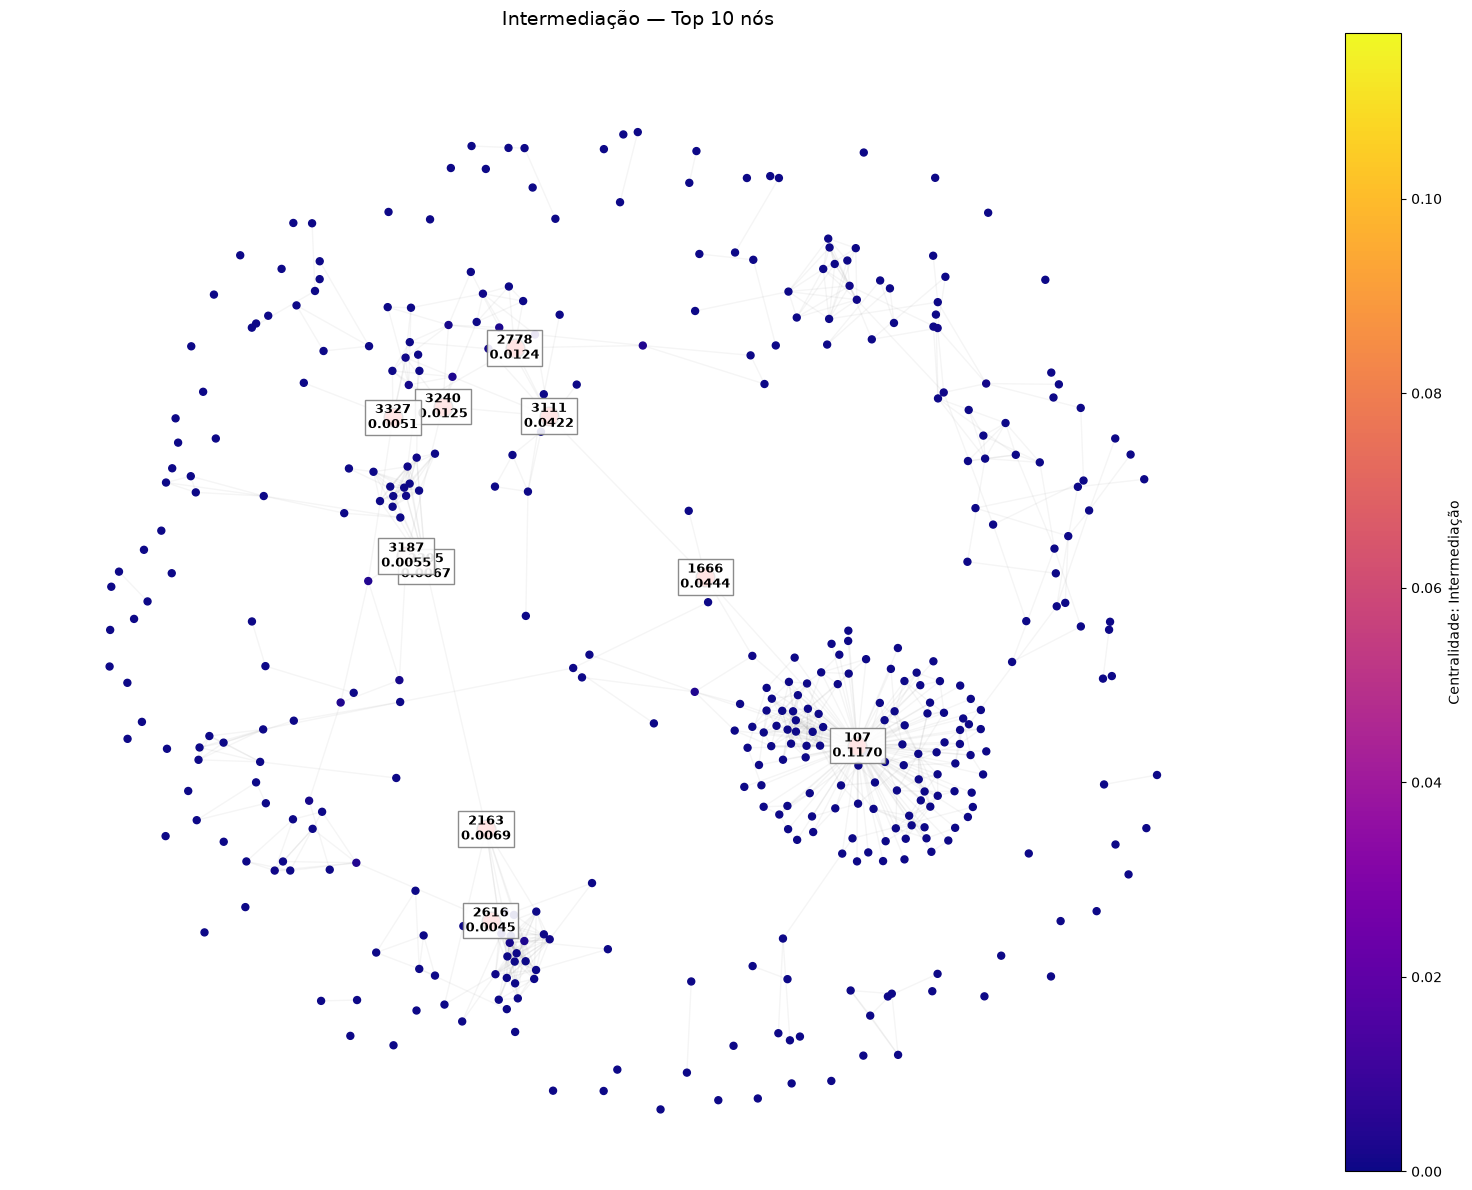

In [15]:
top_betweenness_centrality = display_centrality(
    G=subgraph_sample,
    pos=nodes_positions,
    metrics=nodes_betweenness,
    metric_name="Intermediação",
)

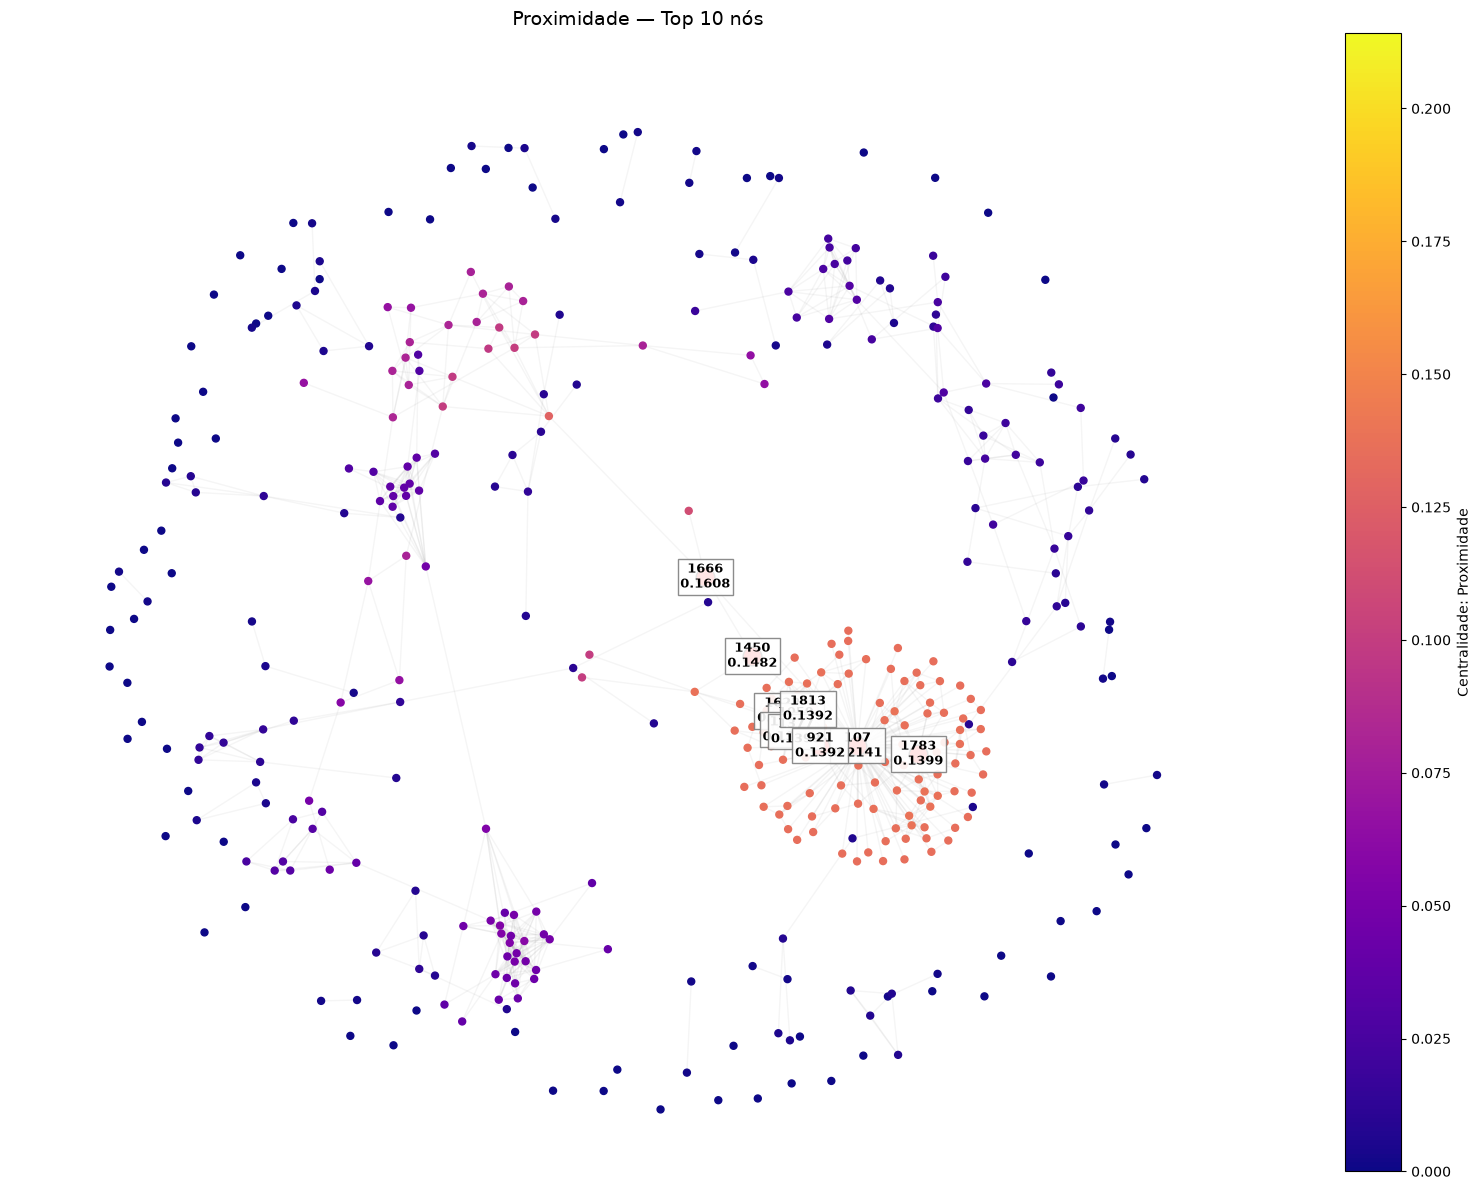

In [16]:
top_closeness_centrality = display_centrality(
    G=subgraph_sample,
    pos=nodes_positions,
    metrics=nodes_closeness,
    metric_name="Proximidade",
)

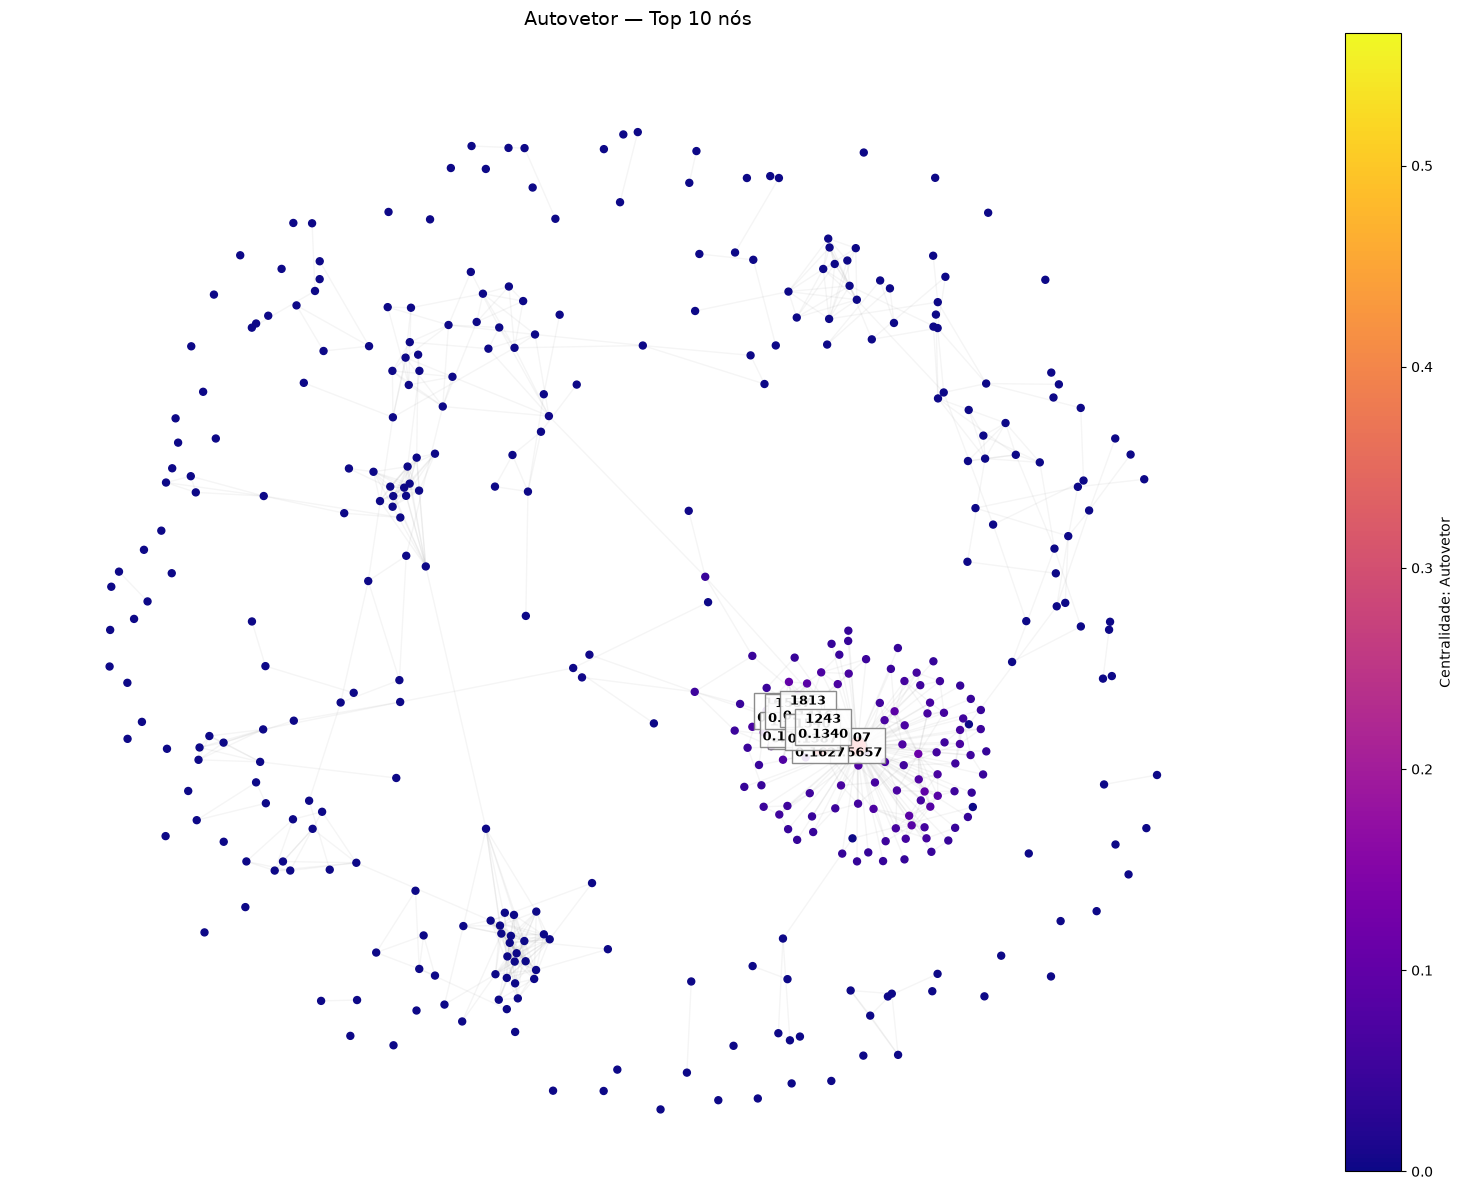

In [17]:
top_eigenvector_centrality = display_centrality(
    G=subgraph_sample,
    pos=nodes_positions,
    metrics=eigenvector_centrality_scores,
    metric_name="Autovetor",
)

## Visualização no navegador com Pyvis (HTML)

Recursos dos grafos interativos:

- Os nós em vermelho são os 10 maiores valores da métrica selecionada;
- O rótulo desses nós apresenta o ID e o valor da métrica;
- Os demais nós recebem cores gradientes conforme o valor e mostram seus IDs.


In [18]:
# Função utilitária para otimizar o carregamento instantâneo e fluidez
def optimize_pyvis_html(html_path: Path):

    content = html_path.read_text(encoding="utf-8")

    # Remove dependências externas bloqueantes de rede
    content = re.sub(
        r"\s*<link[^>]*bootstrap[^>]*>\s*", "\n", content, flags=re.IGNORECASE
    )
    content = re.sub(
        r"\s*<script[^>]*bootstrap[^>]*></script>\s*",
        "\n",
        content,
        flags=re.IGNORECASE,
    )

    # Oculta a barra de carregamento e remove margens/bordas
    custom_style = (
        "<style>"
        "body, html { margin: 0; padding: 0; overflow: hidden; height: 100%; } "
        ".card { border: none !important; margin: 0 !important; } "
        "#loadingBar { display: none !important; }"
        "</style>"
    )

    if "#loadingBar { display: none !important; }" not in content:
        if "<style>body, html { margin: 0;" in content:
            content = re.sub(
                r"<style>body, html \{ margin: 0;.*?</style>", custom_style, content
            )

        else:
            content = content.replace("<body", f"{custom_style}<body", 1)

    # Enquadra o grafo imediatamente na tela após instanciar a rede
    if (
        "network = new vis.Network(container, data, options);" in content
        and "network.fit({ animation: false });" not in content
    ):
        content = content.replace(
            "network = new vis.Network(container, data, options);",
            "network = new vis.Network(container, data, options);\n                  network.fit({ animation: false });",
        )

    # Injeta listener de comandos postMessage para integração segura com o painel
    message_listener_code = """
			  window.network = network;
			  window.addEventListener("message", function(event) {
				  if (!event.data || typeof event.data !== "object") return;
				  if (typeof network === "undefined" || !network) return;
				  if (event.data.action === "fit") {
					  network.fit({ animation: { duration: 400, easingFunction: "easeInOutQuad" } });
				  } else if (event.data.action === "setPhysics") {
					  if (event.data.enabled) {
						  network.setOptions({ physics: { enabled: true } });
						  if (typeof network.startSimulation === "function") network.startSimulation();
					  } else {
						  network.setOptions({ physics: { enabled: false } });
						  if (typeof network.stopSimulation === "function") network.stopSimulation();
					  }
				  }
			  });
"""

    if 'window.addEventListener("message"' not in content:
        content = content.replace(
            "drawGraph();", f"drawGraph();\n{message_listener_code}"
        )

    html_path.write_text(content, encoding="utf-8")


def configure_pyvis_options(
    net: Network, pos: dict | None = None, scale: float = 2000.0
):

    # Injeta coordenadas (x, y) pré-calculadas para renderização instantânea sem custo de CPU na abertura
    if pos is not None:
        for node in net.nodes:
            node_id = node["id"]

            if node_id in pos:
                node["x"] = round(float(pos[node_id][0]) * scale, 2)
                node["y"] = round(float(-pos[node_id][1]) * scale, 2)

    # Desativa improvedLayout e inicia com física pré-estabilizada
    net.options.layout = Layout(randomSeed=RANDOM_SEED, improvedLayout=False)
    net.options.layout.hierarchical.enabled = False
    net.options.edges.smooth.enabled = False
    net.options.interaction.hideEdgesOnDrag = True
    net.options.physics.enabled = False
    net.options.physics.stabilization.enabled = False


# Gera um grafo interativo da rede base
interactive_graph = Network(
    height="100vh",
    width="100%",
    bgcolor="white",
    font_color=True,
    cdn_resources="in_line",
)

for node in subgraph_sample.nodes():
    interactive_graph.add_node(
        node,
        label=str(node),
        title=f"Nó: {node}<br>Comunidade: {community_by_node[node]}<br>Grau: {nodes_degrees[node]:.4f}",
        color="#97c2fc",
        size=10,
        font={"size": 10, "color": True},
    )

interactive_graph.add_edges(subgraph_sample.edges())
configure_pyvis_options(interactive_graph, pos=nodes_positions)

html_export_path = OUTPUT_HTML_DIR / "generated_graph.html"

interactive_graph.write_html(str(html_export_path))
optimize_pyvis_html(html_export_path)

print(f"Grafo interativo base salvo em: {html_export_path}")

Grafo interativo base salvo em: ../metrics/html/generated_graph.html


In [19]:
# Função auxiliar para gerar visualizações interativas em HTML para cada métrica
def render_visualization_metrics(
    G: nx.Graph,
    metrics: dict,
    metric_name: str,
    pos: dict = nodes_positions,
    top_k: int = 10,
):

    highest_metrics = sorted(metrics.items(), key=lambda item: item[1], reverse=True)[
        :top_k
    ]

    top_metric_nodes = {node for node, _ in highest_metrics}

    lowest_metric = min(metrics.values())
    highest_metric = max(metrics.values())

    graph_representation = Network(
        height="100vh",
        width="100%",
        bgcolor="white",
        font_color=True,
        cdn_resources="in_line",
    )

    for node in G.nodes():
        value = metrics[node]

        proportion_value = (
            (value - lowest_metric) / (highest_metric - lowest_metric)
            if highest_metric > lowest_metric
            else 0.5
        )

        color: tuple | str = colorsys.hsv_to_rgb(
            h=0.7 * (1 - proportion_value), s=0.85, v=0.95
        )

        color = f"#{int(color[0] * 255):02x}{int(color[1] * 255):02x}{int(color[2] * 255):02x}"

        is_top_metric_node = node in top_metric_nodes
        node_label = f"{node}\n{value:.4f}" if is_top_metric_node else str(node)

        graph_representation.add_node(
            node,
            label=node_label,
            title=f"Nó: {node}<br>{metric_name}: {value:.6f}",
            color="red" if is_top_metric_node else color,
            size=28 if is_top_metric_node else 10,
            font={"size": 16 if is_top_metric_node else 10, "color": True},
        )

    graph_representation.add_edges(G.edges())
    configure_pyvis_options(graph_representation, pos=pos)

    file_name = metric_name.lower().replace(" ", "_")
    html_file_path = OUTPUT_HTML_DIR / f"{file_name}.html"

    graph_representation.write_html(str(html_file_path))
    optimize_pyvis_html(html_file_path)

    print(f"Arquivo HTML gerado: {html_file_path}")

    return highest_metrics


# Função auxiliar para gerar visualização interativa das comunidades
def render_communities(G: nx.Graph, community_dict: dict, pos: dict = nodes_positions):

    visualization_graph = Network(
        height="100vh",
        width="100%",
        bgcolor="white",
        font_color=True,
        cdn_resources="in_line",
    )

    for node in G.nodes():
        community_id = community_dict[node]

        rgb_value = colorsys.hsv_to_rgb((community_id % 20) / 20.0, 0.75, 0.9)
        hex_color = f"#{int(rgb_value[0] * 255):02x}{int(rgb_value[1] * 255):02x}{int(rgb_value[2] * 255):02x}"

        visualization_graph.add_node(
            node,
            label=str(node),
            title=f"Nó: {node}<br>Comunidade: {community_id}",
            color=hex_color,
            size=12,
            font={"color": True},
        )

    visualization_graph.add_edges(G.edges())
    configure_pyvis_options(visualization_graph, pos=pos)

    output_file_path = OUTPUT_HTML_DIR / "louvain_communities.html"

    visualization_graph.write_html(str(output_file_path))
    optimize_pyvis_html(output_file_path)

    print(f"Arquivo de comunidades gerado: {output_file_path}")

In [20]:
# Gera os arquivos HTML auxiliares
render_visualization_metrics(subgraph_sample, nodes_degrees, "Degree")
render_visualization_metrics(subgraph_sample, nodes_betweenness, "Betweenness")
render_visualization_metrics(subgraph_sample, nodes_closeness, "Closeness")
render_visualization_metrics(
    subgraph_sample, eigenvector_centrality_scores, "Eigenvector"
)

render_communities(subgraph_sample, community_by_node)

Arquivo HTML gerado: ../metrics/html/degree.html
Arquivo HTML gerado: ../metrics/html/betweenness.html
Arquivo HTML gerado: ../metrics/html/closeness.html
Arquivo HTML gerado: ../metrics/html/eigenvector.html
Arquivo de comunidades gerado: ../metrics/html/louvain_communities.html


# Geração das Figuras para o Relatório


In [21]:
# Figura 1: Painel Topologia Inicial vs Comunidades de Louvain
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))

# A) Subgrafo Amostrado Inicial
ax = axes[0]

nx.draw_networkx_edges(
    subgraph_sample, nodes_positions, ax=ax, alpha=0.25, edge_color="gray"
)

nx.draw_networkx_nodes(
    subgraph_sample,
    nodes_positions,
    ax=ax,
    node_size=35,
    node_color="skyblue",
    edgecolors="steelblue",
    linewidths=0.5,
    alpha=0.85,
)

ax.set_title("A) Topologia do Subgrafo Amostrado", fontsize=13, fontweight="bold")
ax.axis("off")

# B) Comunidades de Louvain
ax = axes[1]

community_colors = [community_by_node[n] for n in subgraph_sample.nodes()]

nx.draw_networkx_edges(
    subgraph_sample, nodes_positions, ax=ax, alpha=0.20, edge_color="gray"
)

nx.draw_networkx_nodes(
    subgraph_sample,
    nodes_positions,
    ax=ax,
    node_size=40,
    node_color=community_colors,
    cmap=plt.cm.tab20,
    edgecolors="black",
    linewidths=0.3,
)

community_count = df_metrics["comunidade"].nunique()

ax.set_title(
    "B) Comunidades Detectadas pelo Algoritmo de Louvain",
    fontsize=13,
    fontweight="bold",
)

ax.axis("off")

plt.tight_layout()
plt.savefig(
    OUTPUT_IMAGES_DIR / "fig1_topologia_comunidades.png", dpi=200, bbox_inches="tight"
)

plt.close()

print(f"Figura 1 gerada: {OUTPUT_IMAGES_DIR / 'fig1_topologia_comunidades.png'}")

Figura 1 gerada: ../images/fig1_topologia_comunidades.png


In [22]:
# Figura 2: Painel dos Mapas Espaciais de Centralidade
connected_nodes = [n for n, d in subgraph_sample.degree() if d > 0]

subgraph_connected = subgraph_sample.subgraph(connected_nodes)

pos_connected = nx.spring_layout(
    subgraph_connected, seed=RANDOM_SEED, k=0.22, iterations=70
)

fig, axes = plt.subplots(2, 2, figsize=(16, 13))

centrality_configs = [
    (nodes_degrees, "Grau de Centralidade (Degree)", axes[0, 0]),
    (nodes_betweenness, "Centralidade de Intermediação (Betweenness)", axes[0, 1]),
    (nodes_closeness, "Centralidade de Proximidade (Closeness)", axes[1, 0]),
    (
        eigenvector_centrality_scores,
        "Centralidade de Autovetor (Eigenvector)",
        axes[1, 1],
    ),
]

for metric_dict, title_str, ax in centrality_configs:
    sub_metric = {n: metric_dict[n] for n in subgraph_connected.nodes()}
    top5_items = sorted(sub_metric.items(), key=lambda x: x[1], reverse=True)[:5]
    top5_nodes = [n for n, _ in top5_items]
    node_vals = [sub_metric[n] for n in subgraph_connected.nodes()]

    nx.draw_networkx_edges(
        subgraph_connected, pos_connected, ax=ax, alpha=0.15, edge_color="gray"
    )

    nodes_artist = nx.draw_networkx_nodes(
        subgraph_connected,
        pos_connected,
        ax=ax,
        node_color=node_vals,
        cmap=plt.cm.plasma,
        node_size=35,
        alpha=0.85,
    )

    nx.draw_networkx_nodes(
        subgraph_connected,
        pos_connected,
        ax=ax,
        nodelist=top5_nodes,
        node_color="red",
        node_size=160,
        edgecolors="black",
        linewidths=1.2,
    )

    labels = {n: f"{n}\n({sub_metric[n]:.3f})" for n in top5_nodes}

    nx.draw_networkx_labels(
        subgraph_connected,
        pos_connected,
        labels=labels,
        ax=ax,
        font_size=8,
        font_weight="bold",
        bbox={"facecolor": "white", "edgecolor": "black", "alpha": 0.85, "pad": 1.5},
    )

    cbar = plt.colorbar(nodes_artist, ax=ax, fraction=0.03, pad=0.02)
    cbar.ax.tick_params(labelsize=8)

    ax.set_title(f"{title_str}", fontsize=12, fontweight="bold")

    ax.axis("off")

plt.suptitle(
    f"Visualização Espacial das Medidas de Centralidade (Componentes Conexas, N = {len(connected_nodes)})",
    fontsize=15,
    fontweight="bold",
    y=0.99,
)

plt.tight_layout()

plt.savefig(
    OUTPUT_IMAGES_DIR / "fig2_mapas_centralidade.png", dpi=200, bbox_inches="tight"
)

plt.close()

print(f"Figura 2 gerada: {OUTPUT_IMAGES_DIR / 'fig2_mapas_centralidade.png'}")

Figura 2 gerada: ../images/fig2_mapas_centralidade.png


In [23]:
# Figura 3: Scatter Grau vs Intermediação
fig, axes = plt.subplots(1, 2, figsize=(15.5, 6.2))

ax = axes[0]
ax.grid(True, linestyle="--", alpha=0.4)

sc = ax.scatter(
    df_metrics["grau"],
    df_metrics["intermediacao"],
    c=df_metrics["proximidade"],
    cmap="viridis",
    s=65,
    alpha=0.85,
    edgecolors="black",
    linewidth=0.6,
)

cbar = plt.colorbar(sc, ax=ax, pad=0.02)
cbar.set_label("Centralidade de Proximidade", fontsize=10, fontweight="bold")

ax.set_xlabel(
    "Grau de Centralidade (Popularidade Local)", fontsize=11, fontweight="bold"
)

ax.set_ylabel(
    "Centralidade de Intermediação (Controle de Fluxo)", fontsize=11, fontweight="bold"
)

ax.set_title(
    "A) Relação entre Grau e Intermediação",
    fontsize=12,
    fontweight="bold",
)

ax.set_xlim(-0.015, 0.32)
ax.set_ylim(-0.012, 0.13)

annotations = {
    107: (-0.075, -0.014),
    1666: (0.022, 0.010),
    3111: (0.025, -0.006),
    3240: (0.025, 0.014),
    2778: (0.095, 0.012),
    2328: (0.045, 0.002),
    2511: (0.040, -0.009),
}

for node_id, (dx, dy) in annotations.items():
    row_match = df_metrics[df_metrics["no"] == node_id]

    if not row_match.empty:
        row = row_match.iloc[0]

        ax.annotate(
            f"Nó {int(node_id)} ({int(row['comunidade'])})",
            (row["grau"], row["intermediacao"]),
            xytext=(row["grau"] + dx, row["intermediacao"] + dy),
            fontsize=8.5,
            fontweight="bold",
            bbox={
                "boxstyle": "round,pad=0.2",
                "fc": "white",
                "ec": "gray",
                "alpha": 0.9,
            },
            arrowprops={"arrowstyle": "->", "color": "crimson", "lw": 1.2},
        )

ax = axes[1]

ax.grid(True, axis="y", linestyle="--", alpha=0.4)

comm_counts = df_metrics["comunidade"].value_counts().head(10)

bars = ax.bar(
    [f"Com. {c}" for c in comm_counts.index],
    comm_counts.values,
    color="steelblue",
    edgecolor="black",
    alpha=0.85,
)

ax.set_xlabel("Identificador da Comunidade", fontsize=11, fontweight="bold")
ax.set_ylabel("Quantidade de Usuários", fontsize=11, fontweight="bold")

ax.set_title(
    "B) Distribuição das 10 Maiores Comunidades Detectadas",
    fontsize=12,
    fontweight="bold",
)

for bar in bars:
    h = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        h + 1,
        str(int(h)),
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold",
    )

ax.set_ylim(0, max(comm_counts.values) * 1.15)
ax.tick_params(axis="x", rotation=15)

plt.tight_layout()

plt.savefig(
    OUTPUT_IMAGES_DIR / "fig3_analise_estrutural.png", dpi=200, bbox_inches="tight"
)

plt.close()

print(f"Figura 3 gerada: {OUTPUT_IMAGES_DIR / 'fig3_analise_estrutural.png'}")

Figura 3 gerada: ../images/fig3_analise_estrutural.png


In [24]:
# Figura 4: Ranking Comparativo Top 5 por Métrica
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

metrics_bar_info = [
    ("grau", "Grau de Centralidade", "#1f77b4"),
    ("intermediacao", "Centralidade de Intermediação", "#ff7f0e"),
    ("proximidade", "Centralidade de Proximidade", "#2ca02c"),
    ("autovetor", "Centralidade de Autovetor", "#d62728"),
]

for ax, (col, title, color) in zip(axes.flatten(), metrics_bar_info):
    ax.grid(True, axis="x", linestyle="--", alpha=0.4)

    top5 = df_metrics.sort_values(by=col, ascending=False).head(5)

    y_labels = [
        f"Nó {int(n)} (Com. {int(c)})" for n, c in zip(top5["no"], top5["comunidade"])
    ][::-1]

    x_vals = top5[col].values[::-1]

    bars = ax.barh(y_labels, x_vals, color=color, alpha=0.85, edgecolor="black")

    ax.set_title(f"Top 5 — {title}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Valor da Métrica", fontsize=10)

    for bar in bars:
        w = bar.get_width()

        ax.text(
            w * 1.02,
            bar.get_y() + bar.get_height() / 2,
            f"{w:.4f}",
            va="center",
            ha="left",
            fontsize=9,
            fontweight="bold",
        )

    ax.set_xlim(0, top5[col].max() * 1.22)

plt.suptitle(
    "Síntese Comparativa dos Top 5 Nós por Métrica de Centralidade",
    fontsize=14,
    fontweight="bold",
    y=0.98,
)

plt.tight_layout()

plt.savefig(
    OUTPUT_IMAGES_DIR / "fig4_top5_centralidades.png", dpi=200, bbox_inches="tight"
)

plt.close()


print(f"Figura 4 gerada: {OUTPUT_IMAGES_DIR / 'fig4_top5_centralidades.png'}")

Figura 4 gerada: ../images/fig4_top5_centralidades.png
